<a href="https://colab.research.google.com/github/irmcm/ecg-diffusion-1d/blob/main/ECG_Diffusion_DDPM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1D DDPM on Single-Lead ECG Beats

Training and evaluating a 1D Denoising Diffusion Probabilistic Model (DDPM) on real ECG beats from the MIT-BIH Arrhythmia Database (record 100, MLII lead, 360 Hz).

* **Data Split:** Chronological split (60% train / 10% val / 30% test) with no window overlap across boundaries.
* **Training:** Normal (`N`) beats only. Amplitude scaling and PCA baselines are fitted strictly on the training split.
* **Architecture:** 1D U-Net with pre-activation ResBlocks, GroupNorm, sinusoidal time embeddings, fixed positional coordinate channels, cosine beta schedule, and EMA weights.
* **Evaluation:** RBF-kernel $\text{MMD}^2$ and 1-D Wasserstein distances on morphological features (R-peak amplitude, S-wave trough, T-wave peak, and QRS width), benchmarked against Gaussian template and PCA-Gaussian baselines.

In [ ]:
%pip install -q wfdb pooch

In [ ]:
import os, math, time, random, copy, json, urllib.request, warnings
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import wfdb
from scipy import signal as sps, stats, datasets
from scipy.spatial.distance import pdist
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})

SEED = 42
QUICK = os.environ.get("QUICK") == "1"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(max(1, os.cpu_count() or 1))

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

seed_all(SEED)
os.makedirs("figures", exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", bbox_inches="tight"); plt.show()

# 256-sample window (~0.71s at 360 Hz): 96 pre-R, 160 post-R
CFG = dict(
    fs=360, pre=96, post=160,
    T=200,
    epochs=2 if QUICK else 120, batch=64, lr=1e-3, ema_decay=0.995,
    n_gen=200 if QUICK else 1200,
    ddpm_t_stars=[20, 40, 80], k_draws=1 if QUICK else 3,
)
FS, PRE, POST = CFG["fs"], CFG["pre"], CFG["post"]
L = PRE + POST
print("device:", DEVICE, "| quick mode:", QUICK)

device: cuda | quick mode: False


## 1. Dataset & Chronological Split (MIT-BIH Record 100)

In [ ]:
DATA_DIR = "mitdb_100"; os.makedirs(DATA_DIR, exist_ok=True)
BASE = "https://raw.githubusercontent.com/MIT-LCP/wfdb-python/master/sample-data/"
for ext in ["dat", "hea", "atr"]:
    path = f"{DATA_DIR}/100.{ext}"
    if not os.path.exists(path):
        urllib.request.urlretrieve(BASE + f"100.{ext}", path)

rec = wfdb.rdrecord(f"{DATA_DIR}/100"); ann = wfdb.rdann(f"{DATA_DIR}/100", "atr")
sig = rec.p_signal[:, 0].astype(np.float64)  # MLII lead (mV)
assert rec.fs == FS
print(f"{rec.sig_name[0]} | {len(sig)/FS/60:.1f} min | {rec.fs} Hz")

sym_all, samp_all = np.array(ann.symbol), np.array(ann.sample)
keep = np.isin(sym_all, ["N", "A", "V"])
samp, sym = samp_all[keep], sym_all[keep]

# Local RR interval ratio
rr = np.diff(samp, prepend=samp[0] - int(0.8 * FS)).astype(float)
rr_ratio = np.array([rr[i] / np.median(rr[max(0, i - 8):i]) if i > 0 else 1.0 for i in range(len(rr))])

ok = (samp - PRE >= 0) & (samp + POST <= len(sig))
samp, sym, rr_ratio = samp[ok], sym[ok], rr_ratio[ok]
X = np.stack([sig[s - PRE:s + POST] for s in samp])
X = X - np.median(X, axis=1, keepdims=True)  # remove baseline offset
y = (sym != "N").astype(int)                 # 0: normal, 1: premature (A/V)

# 60/10/30 chronological split without boundary overlap
b1, b2 = int(0.6 * len(sig)), int(0.7 * len(sig))
tr = samp + POST <= b1
va = (samp - PRE >= b1) & (samp + POST <= b2)
te = samp - PRE >= b2
print(f"{'split':6s} {'beats':>6s} {'N':>6s} {'A':>4s} {'V':>4s}")
for nm, m in [("train", tr), ("val", va), ("test", te)]:
    print(f"{nm:6s} {m.sum():6d} {(sym[m]=='N').sum():6d} {(sym[m]=='A').sum():4d} {(sym[m]=='V').sum():4d}")

# Fit scaling on training normal beats only
isN = y == 0
scale = np.percentile(np.abs(X[tr & isN]), 99.9)
Xn = (X / scale).astype(np.float32)
Xtr, Xva, Xte = Xn[tr & isN], Xn[va & isN], Xn[te & isN]
print(f"scale = {scale:.3f} mV | train N: {len(Xtr)}, val N: {len(Xva)}, test N: {len(Xte)}")

MLII | 30.1 min | 360 Hz
split   beats      N    A    V
train    1367   1352   15    0
val       223    215    8    0
test      679    668   10    1
scale = 1.395 mV | train N: 1352, val N: 215, test N: 668


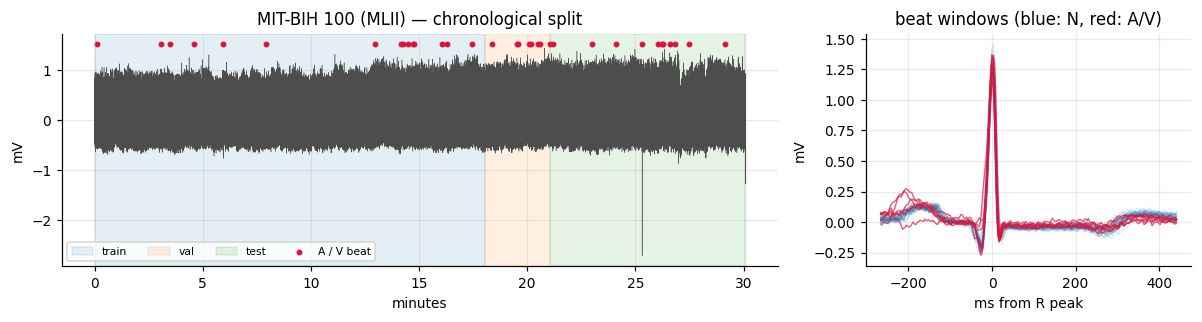

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3), gridspec_kw={"width_ratios": [2.2, 1]})
t = np.arange(len(sig)) / FS / 60
ax[0].plot(t, sig, lw=0.3, color="0.3")
for lo, hi, c, nm in [(0, b1, "tab:blue", "train"), (b1, b2, "tab:orange", "val"), (b2, len(sig), "tab:green", "test")]:
    ax[0].axvspan(lo / FS / 60, hi / FS / 60, color=c, alpha=0.12, label=nm)
ax[0].scatter(samp[y == 1] / FS / 60, np.full((y == 1).sum(), sig.max() * 1.05), s=8, color="crimson", label="A / V beat")
ax[0].set(title="MIT-BIH 100 (MLII) — chronological split", xlabel="minutes", ylabel="mV"); ax[0].legend(ncol=4, fontsize=7)
xs = (np.arange(L) - PRE) / FS * 1000
for i in np.where(tr & isN)[0][:40]: ax[1].plot(xs, X[i], color="tab:blue", alpha=0.15, lw=0.7)
for i in np.where(y == 1)[0][:6]: ax[1].plot(xs, X[i], color="crimson", alpha=0.7, lw=0.9)
ax[1].set(title="beat windows (blue: N, red: A/V)", xlabel="ms from R peak", ylabel="mV")
savefig("01_data_overview")

### Cross-Patient Reference (MIT-BIH Record 208)
Used as an out-of-distribution reference for MMD evaluation. R-peaks are extracted via bandpass filtering (5-15 Hz) and normalized by their 99.9th percentile.

In [ ]:
ecg2 = datasets.electrocardiogram().astype(np.float64)
sos = sps.butter(2, [5, 15], btype="bandpass", fs=FS, output="sos")
env = sps.sosfiltfilt(sos, ecg2) ** 2
pk, _ = sps.find_peaks(env, height=np.percentile(env, 92), distance=int(0.3 * FS))
pk = np.array([p - 12 + np.argmax(np.abs(ecg2[p - 12:p + 13] - np.median(ecg2[p - 12:p + 13]))) for p in pk if 12 <= p < len(ecg2) - 12])
pk = pk[(pk - PRE >= 0) & (pk + POST <= len(ecg2))]
X2 = np.stack([ecg2[p - PRE:p + POST] for p in pk]); X2 = X2 - np.median(X2, axis=1, keepdims=True)
X2n = (X2 / np.percentile(np.abs(X2), 99.9)).astype(np.float32)
print(f"record 208 reference: {len(X2n)} beats detected in {len(ecg2)/FS/60:.1f} min -> {len(X2n)/(len(ecg2)/FS/60):.0f} beats/min")

record 208 reference: 484 beats detected in 5.0 min -> 97 beats/min


## 2. 1D U-Net & Diffusion Architecture

In [ ]:
class SinEmb(nn.Module):
    def __init__(self, dim): super().__init__(); self.dim = dim
    def forward(self, t):
        half = self.dim // 2
        f = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / (half - 1))
        a = t[:, None].float() * f[None]
        return torch.cat([a.sin(), a.cos()], dim=-1)

class ResBlock(nn.Module):
    def __init__(self, cin, cout, tdim, groups=8):
        super().__init__()
        self.n1, self.c1 = nn.GroupNorm(groups, cin), nn.Conv1d(cin, cout, 3, padding=1)
        self.t = nn.Linear(tdim, cout)
        self.n2, self.c2 = nn.GroupNorm(groups, cout), nn.Conv1d(cout, cout, 3, padding=1)
        self.skip = nn.Conv1d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x, t):
        h = self.c1(F.silu(self.n1(x)))
        h = h + self.t(F.silu(t))[:, :, None]
        h = self.c2(F.silu(self.n2(h)))
        return h + self.skip(x)

def coord_channels(n, length, device):
    # Positional encoding channels to anchor R-peak alignment
    u = torch.linspace(0, 1, length, device=device)
    c = torch.stack([2 * u - 1, torch.sin(2 * math.pi * u), torch.cos(2 * math.pi * u),
                     torch.sin(4 * math.pi * u), torch.cos(4 * math.pi * u)])
    return c[None].expand(n, -1, -1)

class UNet1D(nn.Module):
    def __init__(self, length, ch=(32, 64, 128), tdim=128):
        super().__init__()
        self.temb = nn.Sequential(SinEmb(64), nn.Linear(64, tdim), nn.SiLU(), nn.Linear(tdim, tdim))
        self.inc = nn.Conv1d(1 + 5, ch[0], 3, padding=1)
        self.mid_pos = nn.Parameter(torch.randn(1, ch[-1], length // 2 ** len(ch)) * 0.02)
        cs = [ch[0]] + list(ch)
        self.down = nn.ModuleList([ResBlock(cs[i], cs[i + 1], tdim) for i in range(len(ch))])
        self.pool = nn.ModuleList([nn.Conv1d(c, c, 3, stride=2, padding=1) for c in ch])
        self.mid1, self.mid2 = ResBlock(ch[-1], ch[-1], tdim), ResBlock(ch[-1], ch[-1], tdim)
        rev = list(ch)[::-1]
        outs = list(ch)[::-1][1:] + [ch[0]]
        self.up = nn.ModuleList([ResBlock(rev[i] + rev[i], outs[i], tdim) for i in range(len(ch))])
        self.out = nn.Sequential(nn.GroupNorm(8, ch[0]), nn.SiLU(), nn.Conv1d(ch[0], 1, 3, padding=1))
    def forward(self, x, t):
        te = self.temb(t)
        h = self.inc(torch.cat([x, coord_channels(len(x), x.shape[-1], x.device)], 1)); skips = []
        for blk, pool in zip(self.down, self.pool):
            h = blk(h, te); skips.append(h); h = pool(h)
        h = self.mid2(self.mid1(h + self.mid_pos, te), te)
        for blk in self.up:
            h = F.interpolate(h, scale_factor=2, mode="nearest")
            h = blk(torch.cat([h, skips.pop()], 1), te)
        return self.out(h)

def cosine_betas(T, s=0.008):
    steps = torch.arange(T + 1, dtype=torch.float64)
    f = torch.cos((steps / T + s) / (1 + s) * math.pi / 2) ** 2
    ab = f / f[0]
    return (1 - ab[1:] / ab[:-1]).clamp(1e-5, 0.999).float()

class Diffusion:
    def __init__(self, T, device, clip=1.5):
        self.T, self.clip = T, clip
        b = cosine_betas(T).to(device); a = 1 - b; ab = torch.cumprod(a, 0)
        abp = torch.cat([torch.ones(1, device=device), ab[:-1]])
        self.b, self.a, self.ab, self.abp = b, a, ab, abp
        self.post_var = b * (1 - abp) / (1 - ab)
        self.c0 = b * abp.sqrt() / (1 - ab)
        self.ct = (1 - abp) * a.sqrt() / (1 - ab)
    def q_sample(self, x0, t, eps):
        ab = self.ab[t].view(-1, 1, 1)
        return ab.sqrt() * x0 + (1 - ab).sqrt() * eps
    def loss(self, model, x0, t=None, eps=None):
        t = torch.randint(0, self.T, (len(x0),), device=x0.device) if t is None else t
        eps = torch.randn_like(x0) if eps is None else eps
        return F.mse_loss(model(self.q_sample(x0, t, eps), t), eps)
    @torch.no_grad()
    def reverse(self, model, x, t_start, keep_at=()):
        # Posterior sampling with x0 reconstruction and clamping
        traj = {}
        for i in range(t_start, -1, -1):
            t = torch.full((len(x),), i, device=x.device, dtype=torch.long)
            eps = model(x, t)
            x0 = ((x - (1 - self.ab[i]).sqrt() * eps) / self.ab[i].sqrt()).clamp(-self.clip, self.clip)
            x = self.c0[i] * x0 + self.ct[i] * x
            if i > 0: x = x + self.post_var[i].sqrt() * torch.randn_like(x)
            if i in keep_at: traj[i] = x.cpu().numpy()[:, 0]
        return (x, traj) if keep_at else x

class EMA:
    def __init__(self, model, decay):
        self.m, self.decay = copy.deepcopy(model).eval(), decay
        for p in self.m.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model, step):
        d = min(self.decay, (1 + step) / (10 + step))
        for ps, p in zip(self.m.parameters(), model.parameters()): ps.mul_(d).add_(p.detach(), alpha=1 - d)

net = UNet1D(L).to(DEVICE)
diff = Diffusion(CFG["T"], DEVICE)
print(f"parameters: {sum(p.numel() for p in net.parameters())/1e6:.2f} M")

parameters: 0.59 M


## 3. Training Loop
Validation MSE is evaluated using EMA weights over a fixed noise seed and stratified timestep grid.

In [ ]:
CKPT = "ecg_ddpm_ema.pt"
dl_x = torch.tensor(Xtr)[:, None, :].to(DEVICE)
xv = torch.tensor(Xva)[:, None, :].to(DEVICE)
g = torch.Generator().manual_seed(123)
val_eps = torch.randn(xv.shape, generator=g).to(DEVICE); val_t = (torch.arange(len(xv)) % CFG["T"]).to(DEVICE)

ema = EMA(net, CFG["ema_decay"])
if os.path.exists(CKPT) and not QUICK:
    ck = torch.load(CKPT, map_location=DEVICE); ema.m.load_state_dict(ck["ema"]); hist = ck["hist"]
    print("loaded checkpoint, skipping training")
else:
    seed_all(SEED)
    opt = torch.optim.AdamW(net.parameters(), lr=CFG["lr"], weight_decay=1e-4)
    steps_per_epoch = math.ceil(len(dl_x) / CFG["batch"]); total = steps_per_epoch * CFG["epochs"]
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total)
    hist = {"train": [], "val": []}; step = 0; t0 = time.time()
    for ep in range(CFG["epochs"]):
        net.train(); perm = torch.randperm(len(dl_x), device=DEVICE); run = 0.0
        for i in range(0, len(perm), CFG["batch"]):
            xb = dl_x[perm[i:i + CFG["batch"]]]
            loss = diff.loss(net, xb)
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step(); sched.step()
            ema.update(net, step); step += 1; run += loss.item() * len(xb)
        with torch.no_grad(): v = diff.loss(ema.m, xv, t=val_t, eps=val_eps).item()
        hist["train"].append(run / len(dl_x)); hist["val"].append(v)
        if (ep + 1) % 10 == 0 or ep == 0:
            print(f"epoch {ep+1:3d}/{CFG['epochs']} | train {hist['train'][-1]:.4f} | val(EMA) {v:.4f} | {time.time()-t0:.0f}s")
    if not QUICK: torch.save({"ema": ema.m.state_dict(), "hist": hist}, CKPT)
model = ema.m.eval()

epoch   1/120 | train 0.3057 | val(EMA) 0.0761 | 4s
epoch  10/120 | train 0.0127 | val(EMA) 0.0165 | 10s
epoch  20/120 | train 0.0103 | val(EMA) 0.0140 | 17s
epoch  30/120 | train 0.0085 | val(EMA) 0.0130 | 25s
epoch  40/120 | train 0.0094 | val(EMA) 0.0123 | 36s
epoch  50/120 | train 0.0071 | val(EMA) 0.0119 | 45s
epoch  60/120 | train 0.0077 | val(EMA) 0.0115 | 50s
epoch  70/120 | train 0.0069 | val(EMA) 0.0114 | 54s
epoch  80/120 | train 0.0072 | val(EMA) 0.0112 | 59s
epoch  90/120 | train 0.0072 | val(EMA) 0.0111 | 63s
epoch 100/120 | train 0.0069 | val(EMA) 0.0110 | 67s
epoch 110/120 | train 0.0063 | val(EMA) 0.0109 | 71s
epoch 120/120 | train 0.0063 | val(EMA) 0.0109 | 75s


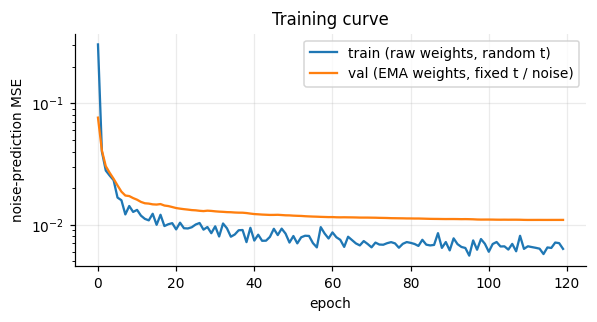

final train 0.0063 | final val 0.0109


In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.plot(hist["train"], label="train (raw weights, random t)"); ax.plot(hist["val"], label="val (EMA weights, fixed t / noise)")
ax.set(xlabel="epoch", ylabel="noise-prediction MSE", title="Training curve", yscale="log"); ax.legend()
savefig("02_training_curve")
print(f"final train {hist['train'][-1]:.4f} | final val {hist['val'][-1]:.4f}")

## 4. Sampling & Baselines
Comparing DDPM samples against two baselines fitted on the training split:
* **Template + Noise:** Per-sample empirical mean and standard deviation with independent Gaussian noise.
* **PCA-Gaussian:** Multivariate Gaussian fitted in a 20-component PCA space (explains 96.0% of training variance).

In [ ]:
@torch.no_grad()
def generate(n, bs=400, seed=SEED + 1):
    torch.manual_seed(seed); out = []
    for i in range(0, n, bs):
        m = min(bs, n - i)
        out.append(diff.reverse(model, torch.randn(m, 1, L, device=DEVICE), CFG["T"] - 1).cpu().numpy()[:, 0])
    return np.concatenate(out)

t0 = time.time(); gen = generate(CFG["n_gen"]); print(f"generated {len(gen)} beats in {time.time()-t0:.0f}s")

rng = np.random.default_rng(SEED)
tmpl = Xtr.mean(0) + Xtr.std(0) * rng.standard_normal((CFG["n_gen"], L)).astype(np.float32)
pca20 = PCA(20, random_state=SEED).fit(Xtr); Z = pca20.transform(Xtr)
pcag = pca20.inverse_transform(rng.multivariate_normal(Z.mean(0), np.cov(Z.T), CFG["n_gen"])).astype(np.float32)
print(f"PCA(20) explains {pca20.explained_variance_ratio_.sum()*100:.1f}% of training variance")

generated 1200 beats in 16s
PCA(20) explains 96.0% of training variance


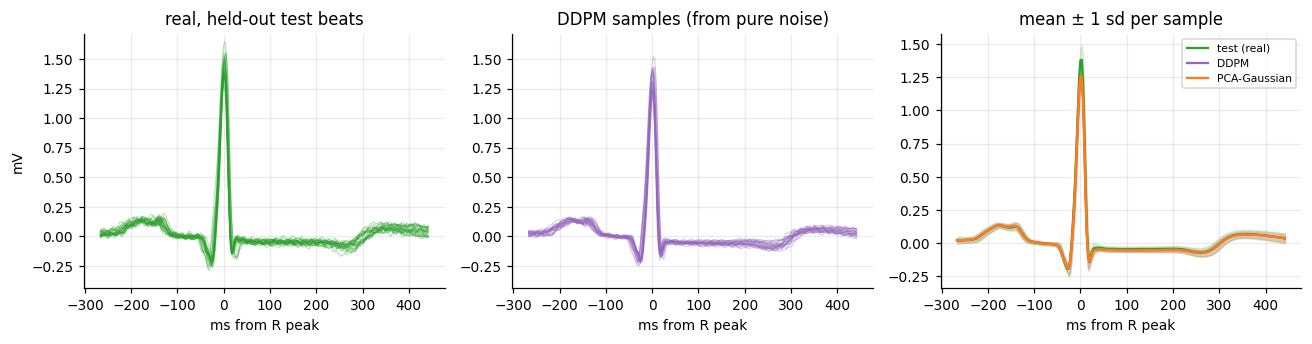

In [ ]:
xs = (np.arange(L) - PRE) / FS * 1000
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for i in range(25): ax[0].plot(xs, Xte[i] * scale, color="tab:green", alpha=0.35, lw=0.7)
ax[0].set(title="real, held-out test beats", xlabel="ms from R peak", ylabel="mV")
for i in range(25): ax[1].plot(xs, gen[i] * scale, color="tab:purple", alpha=0.35, lw=0.7)
ax[1].set(title="DDPM samples (from pure noise)", xlabel="ms from R peak")
for nm, A, c in [("test (real)", Xte, "tab:green"), ("DDPM", gen, "tab:purple"), ("PCA-Gaussian", pcag, "tab:orange")]:
    m, s = A.mean(0) * scale, A.std(0) * scale
    ax[2].plot(xs, m, color=c, label=nm); ax[2].fill_between(xs, m - s, m + s, color=c, alpha=0.15)
ax[2].set(title="mean ± 1 sd per sample", xlabel="ms from R peak"); ax[2].legend(fontsize=7)
for a in ax[:2]: a.set_ylim(ax[2].get_ylim()[0] - 0.1, (np.abs(Xte).max() * scale))
savefig("03_samples")

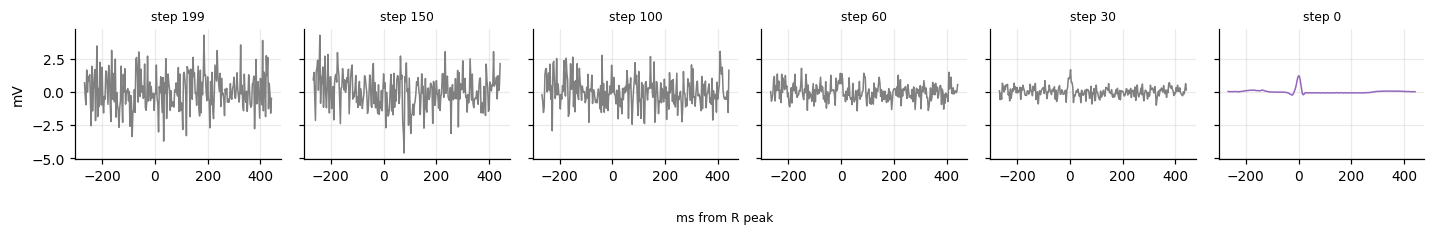

In [ ]:
# one denoising trajectory
torch.manual_seed(SEED + 7)
keep_at = (199, 150, 100, 60, 30, 0)
_, traj = diff.reverse(model, torch.randn(1, 1, L, device=DEVICE), CFG["T"] - 1, keep_at=keep_at)
fig, ax = plt.subplots(1, 6, figsize=(13, 2.1), sharey=True)
for a, k in zip(ax, keep_at):
    a.plot(xs, traj[k][0] * scale, color="tab:purple" if k == 0 else "0.5", lw=1); a.set_title(f"step {k}", fontsize=8)
ax[0].set_ylabel("mV"); fig.supxlabel("ms from R peak", fontsize=8)
savefig("04_denoising_trajectory")

## 5. Quantitative Evaluation
### 5a. Maximum Mean Discrepancy ($\text{MMD}^2$)
Unbiased RBF-kernel $\text{MMD}^2$ (mean ± sd over 4 random subsets of 300 beats) against the held-out test set.

In [ ]:
sigma = float(np.median(pdist(Xtr[:500])))
def rbf_mmd2(A, B, sg):
    A, B = torch.tensor(A), torch.tensor(B)
    k = lambda u, v: torch.exp(-torch.cdist(u, v) ** 2 / (2 * sg ** 2))
    Kaa, Kbb, Kab = k(A, A), k(B, B), k(A, B); n, m = len(A), len(B)
    return ((Kaa.sum() - Kaa.trace()) / (n * (n - 1)) + (Kbb.sum() - Kbb.trace()) / (m * (m - 1)) - 2 * Kab.mean()).item()

def mmd_rows(src, ref, sg, n_sub=300, reps=4, seed=0):
    r = np.random.default_rng(seed); n_sub = min(n_sub, len(src))
    v = [rbf_mmd2(src[r.choice(len(src), n_sub, replace=False)], ref, sg) for _ in range(reps)]
    return np.mean(v), np.std(v)

sources = {"real train beats (floor)": Xtr, "DDPM (EMA)": gen, "PCA-Gaussian": pcag,
           "template + noise": tmpl, "record 208 (other patient)": X2n,
           "white Gaussian noise": rng.standard_normal((300, L)).astype(np.float32) * Xtr.std()}
mmd_res = {k: mmd_rows(v, Xte, sigma) for k, v in sources.items()}
print(f"bandwidth sigma = {sigma:.3f}")
for k, (m, s) in mmd_res.items(): print(f"{k:30s} MMD² = {m:+.4f} ± {s:.4f}")

bandwidth sigma = 0.536
real train beats (floor)       MMD² = +0.0732 ± 0.0057
DDPM (EMA)                     MMD² = +0.0857 ± 0.0030
PCA-Gaussian                   MMD² = +0.0614 ± 0.0016
template + noise               MMD² = +0.0765 ± 0.0031
record 208 (other patient)     MMD² = +0.5581 ± 0.0036
white Gaussian noise           MMD² = +0.4637 ± 0.0000


### 5b. Physiological features (mV / ms)
R amplitude, post-R trough (S-wave depth), T-wave peak, and width of the R peak at half its height.
Distance = 1-D Wasserstein between generated (or train) and test feature distributions, divided by the test feature's sd (0 = identical).

In [ ]:
def beat_features(W):
    x = W * scale
    r_amp = x[:, PRE - 8:PRE + 9].max(1)
    s_dep = x[:, PRE:PRE + 26].min(1)
    t_amp = x[:, PRE + 45:PRE + 150].max(1)
    width = np.full(len(x), np.nan)
    for j, (xi, h) in enumerate(zip(x, r_amp * 0.5)):
        if h <= 0.05: continue
        c = PRE - 8 + int(np.argmax(xi[PRE - 8:PRE + 9])); l = r = c
        while l > 0 and xi[l - 1] > h: l -= 1
        while r < L - 1 and xi[r + 1] > h: r += 1
        width[j] = (r - l + 1) / FS * 1000
    return {"R amplitude (mV)": r_amp, "post-R trough (mV)": s_dep, "T-wave peak (mV)": t_amp, "R width @50% (ms)": width}

feats = {nm: beat_features(A) for nm, A in [("test", Xte), ("train", Xtr), ("DDPM", gen), ("PCA-Gaussian", pcag), ("template + noise", tmpl)]}
rows = []
for f in feats["test"]:
    te_f = feats["test"][f]; te_f = te_f[np.isfinite(te_f)]
    row = {"feature": f, "test mean ± sd": f"{te_f.mean():.3f} ± {te_f.std():.3f}"}
    for nm in ["train", "DDPM", "PCA-Gaussian", "template + noise"]:
        v = feats[nm][f]; ok_ = np.isfinite(v)
        row[nm + " mean ± sd"] = f"{v[ok_].mean():.3f} ± {v[ok_].std():.3f}"
        row[nm + " W1/sd"] = stats.wasserstein_distance(v[ok_], te_f) / te_f.std()
    rows.append(row)
import pandas as pd
ft = pd.DataFrame(rows).set_index("feature")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
print(ft[[c for c in ft.columns if "W1" in c]].round(3).to_string())
print()
print(ft[[c for c in ft.columns if "mean" in c]].to_string())
print("fraction of generated beats with undefined R width:",
      {nm: float(np.mean(~np.isfinite(feats[nm]["R width @50% (ms)"]))) for nm in ["DDPM", "PCA-Gaussian", "template + noise"]})

                    train W1/sd  DDPM W1/sd  PCA-Gaussian W1/sd  template + noise W1/sd
feature                                                                                
R amplitude (mV)          1.271       1.274               1.300                   0.771
post-R trough (mV)        0.680       0.648               0.957                   1.660
T-wave peak (mV)          0.187       0.420               0.378                   1.035
R width @50% (ms)         0.187       0.146               0.267                   0.393

                    test mean ± sd train mean ± sd  DDPM mean ± sd PCA-Gaussian mean ± sd template + noise mean ± sd
feature                                                                                                             
R amplitude (mV)     1.403 ± 0.097   1.280 ± 0.097   1.280 ± 0.095          1.277 ± 0.096              1.329 ± 0.076
post-R trough (mV)  -0.142 ± 0.030  -0.161 ± 0.029  -0.160 ± 0.025         -0.163 ± 0.063             -0.191 ± 0.061
T-w

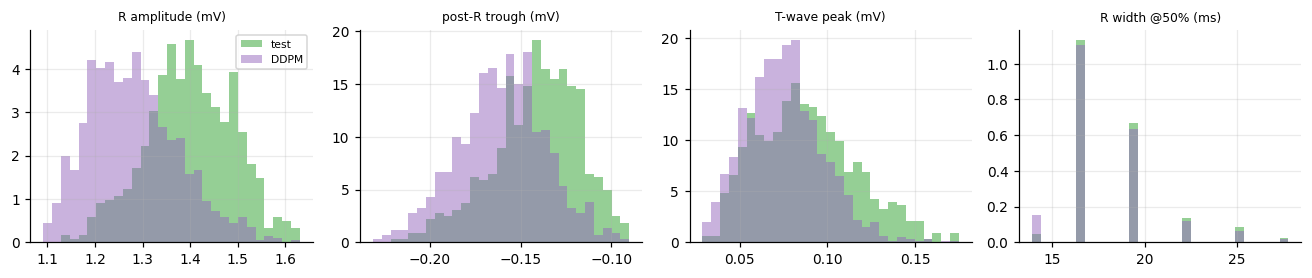

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(12, 2.6))
for a, f in zip(ax, feats["test"]):
    allv = np.concatenate([feats[k][f][np.isfinite(feats[k][f])] for k in ["test", "DDPM"]])
    bins = np.linspace(np.percentile(allv, 0.5), np.percentile(allv, 99.5), 30)
    for nm, c in [("test", "tab:green"), ("DDPM", "tab:purple")]:
        v = feats[nm][f]; a.hist(v[np.isfinite(v)], bins=bins, alpha=0.5, color=c, density=True, label=nm)
    a.set_title(f, fontsize=8)
ax[0].legend(fontsize=7); savefig("05_feature_distributions")

## 5c. Can a classifier tell generated from real?

Gradient-boosted tree classifiers are trained to distinguish *real training beats* from *generated beats*, and then evaluated on held-out *real test beats vs. unseen generated beats* (balanced sets).
* **Oracle Control:** Real training beats pretending to act as generators serve as a sanity floor. An accuracy and AUC near 0.5 confirm that the classifier cannot exploit the train-to-test chronological gap.

In [ ]:
def disc_score(gen_beats, real_fit=Xtr, seed=SEED):
    h = len(gen_beats) // 2; r = np.random.default_rng(seed)
    n_fit = min(h, len(real_fit)); n_eval = min(len(gen_beats) - h, len(Xte))
    Xf = np.concatenate([real_fit[r.choice(len(real_fit), n_fit, replace=False)], gen_beats[:n_fit]])
    yf = np.r_[np.zeros(n_fit), np.ones(n_fit)]
    Xe = np.concatenate([Xte[r.choice(len(Xte), n_eval, replace=False)], gen_beats[h:h + n_eval]])
    ye = np.r_[np.zeros(n_eval), np.ones(n_eval)]
    clf = HistGradientBoostingClassifier(max_iter=200, random_state=seed).fit(Xf, yf)
    p = clf.predict_proba(Xe)[:, 1]
    return ((p > 0.5) == ye).mean(), roc_auc_score(ye, p)
disc = {nm: disc_score(A) for nm, A in [("DDPM (EMA)", gen), ("PCA-Gaussian", pcag), ("template + noise", tmpl)]}
# "oracle generator": a random half of the real training beats plays the generator against the other half.
# It is a perfect model of the training distribution, so any score above 0.5 here is temporal drift, not model error.
perm_ = np.random.default_rng(SEED).permutation(len(Xtr)); half_ = len(Xtr) // 2
disc["oracle (real train beats)"] = disc_score(Xtr[perm_[half_:]], real_fit=Xtr[perm_[:half_]])
for k, (acc, auc) in disc.items(): print(f"{k:18s} accuracy = {acc:.3f} | AUC = {auc:.3f}")

DDPM (EMA)         accuracy = 0.978 | AUC = 0.997
PCA-Gaussian       accuracy = 0.964 | AUC = 0.995
template + noise   accuracy = 0.993 | AUC = 1.000
oracle (real train beats) accuracy = 0.496 | AUC = 0.480


* **Findings:** The classifier successfully separates generated beats from real test beats (performing well above chance level). While the model captures overall shape and beat-to-beat variability, generated beats are consistently smoother than real ones, lacking fine-scale high-frequency sensor texture.

In [ ]:
rough = lambda A: np.median(np.abs(np.diff(A, n=2, axis=1)), axis=1)
print("median |2nd difference| per beat (scaled units), median over beats")
rough_res = {}
for nm, A in [("real test", Xte), ("real train", Xtr), ("DDPM", gen), ("PCA-Gaussian", pcag), ("template + noise", tmpl)]:
    rough_res[nm] = float(np.median(rough(A))); print(f"  {nm:18s} {rough_res[nm]:.5f}")
print(f"DDPM / real-test roughness ratio: {rough_res['DDPM']/rough_res['real test']:.2f}")

median |2nd difference| per beat (scaled units), median over beats
  real test          0.00717
  real train         0.00717
  DDPM               0.00331
  PCA-Gaussian       0.00369
  template + noise   0.02944
DDPM / real-test roughness ratio: 0.46


## 5d. Memorisation check

Given ~1.3k training beats, a diffusion model risks memorising its training data. To check for this, we compute the distance from each generated beat to its nearest training beat and compare it against the same distance for unseen real test beats. A ratio significantly below 1.0 would indicate direct copying.

median distance to nearest training beat | generated: 0.229 | real test: 0.269 | ratio: 0.85
5th percentile                           | generated: 0.186 | real test: 0.209


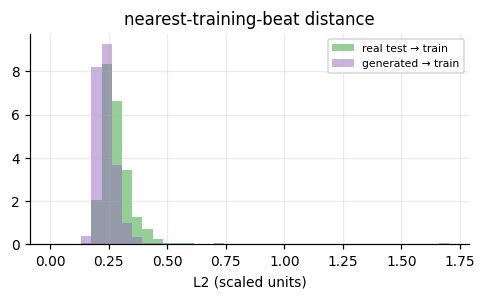

In [ ]:
def nn_dist(A, B):
    return torch.cdist(torch.tensor(A), torch.tensor(B)).min(1).values.numpy()
d_gen, d_te = nn_dist(gen, Xtr), nn_dist(Xte, Xtr)
print(f"median distance to nearest training beat | generated: {np.median(d_gen):.3f} | real test: {np.median(d_te):.3f} | ratio: {np.median(d_gen)/np.median(d_te):.2f}")
print(f"5th percentile                           | generated: {np.percentile(d_gen,5):.3f} | real test: {np.percentile(d_te,5):.3f}")
fig, ax = plt.subplots(figsize=(4.5, 2.8))
b = np.linspace(0, max(d_gen.max(), d_te.max()), 40)
ax.hist(d_te, b, alpha=0.5, color="tab:green", density=True, label="real test → train")
ax.hist(d_gen, b, alpha=0.5, color="tab:purple", density=True, label="generated → train")
ax.set(title="nearest-training-beat distance", xlabel="L2 (scaled units)"); ax.legend(fontsize=7)
savefig("06_memorisation")

## 6. Downstream use: reconstruction error as an anomaly score

The model is trained exclusively on **normal** beats from the first 60% of the recording. For beats in the held-out validation and test sets, each beat is forward-noised to timestep $t^*$ and denoised back. The resulting reconstruction error serves as an anomaly score to detect **premature beats (A or V arrhythmias)**.
* **Evaluation:** Evaluated across three un-tuned timesteps ($t^* \in \{20, 40, 80\}$).
* **Comparators:** PCA reconstruction error and Euclidean distance to the mean training template (both fitted on the same training data). RR-prematurity (previous RR divided by the median of the preceding 8 RRs) is provided as a timing-based context reference.


In [ ]:
held = va | te
Xh, yh = Xn[held], y[held]
print(f"held-out beats: {len(Xh)} (normal {int((yh==0).sum())}, A/V {int(yh.sum())})")

@torch.no_grad()
def ddpm_score(X_, t_star, k=CFG["k_draws"], bs=450, seed=SEED + 11):
    torch.manual_seed(seed); errs = np.zeros(len(X_))
    for _ in range(k):
        for i in range(0, len(X_), bs):
            x0 = torch.tensor(X_[i:i + bs])[:, None, :].to(DEVICE)
            t = torch.full((len(x0),), t_star, device=DEVICE, dtype=torch.long)
            xt = diff.q_sample(x0, t, torch.randn_like(x0))
            rec_ = diff.reverse(model, xt, t_star)
            errs[i:i + bs] += ((rec_ - x0) ** 2).mean((1, 2)).cpu().numpy() / k
    return errs

scores = {}
t0 = time.time()
for ts in CFG["ddpm_t_stars"]:
    scores[f"DDPM recon (t*={ts})"] = ddpm_score(Xh, ts)
print(f"DDPM scoring done in {time.time()-t0:.0f}s")
for kc in (5, 20):
    pk_ = PCA(kc, random_state=SEED).fit(Xtr)
    scores[f"PCA recon (k={kc})"] = ((Xh - pk_.inverse_transform(pk_.transform(Xh))) ** 2).mean(1)
scores["distance to mean template"] = ((Xh - Xtr.mean(0)) ** 2).mean(1)
scores["[context] RR prematurity"] = -rr_ratio[held]

def auc_ci(yv, s, n_boot=1000, seed=0):
    r = np.random.default_rng(seed); pos, neg = np.where(yv == 1)[0], np.where(yv == 0)[0]; v = []
    for _ in range(n_boot):
        idx = np.r_[r.choice(pos, len(pos)), r.choice(neg, len(neg))]
        v.append(roc_auc_score(yv[idx], s[idx]))
    return roc_auc_score(yv, s), np.percentile(v, 2.5), np.percentile(v, 97.5)

auc_tab = {k: auc_ci(yh, v) for k, v in scores.items()}
for k, (a, lo, hi) in auc_tab.items(): print(f"{k:30s} AUROC = {a:.3f}  [{lo:.3f}, {hi:.3f}]")

held-out beats: 902 (normal 883, A/V 19)
DDPM scoring done in 28s
DDPM recon (t*=20)             AUROC = 0.764  [0.618, 0.886]
DDPM recon (t*=40)             AUROC = 0.697  [0.572, 0.820]
DDPM recon (t*=80)             AUROC = 0.648  [0.538, 0.754]
PCA recon (k=5)                AUROC = 0.919  [0.843, 0.971]
PCA recon (k=20)               AUROC = 0.961  [0.938, 0.978]
distance to mean template      AUROC = 0.641  [0.513, 0.765]
[context] RR prematurity       AUROC = 1.000  [1.000, 1.000]


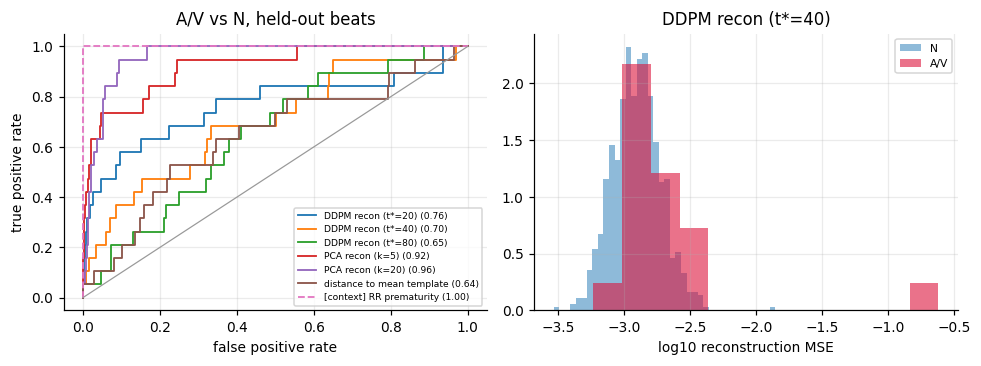

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for k, v in scores.items():
    fpr, tpr, _ = roc_curve(yh, v)
    ax[0].plot(fpr, tpr, lw=1.2, ls="--" if k.startswith("[") else "-", label=f"{k} ({auc_tab[k][0]:.2f})")
ax[0].plot([0, 1], [0, 1], color="0.6", lw=0.8); ax[0].set(xlabel="false positive rate", ylabel="true positive rate", title="A/V vs N, held-out beats"); ax[0].legend(fontsize=6)
k0 = f"DDPM recon (t*={CFG['ddpm_t_stars'][1]})"
ax[1].hist(np.log10(scores[k0][yh == 0]), 40, alpha=0.5, density=True, color="tab:blue", label="N")
ax[1].hist(np.log10(scores[k0][yh == 1]), 12, alpha=0.6, density=True, color="crimson", label="A/V")
ax[1].set(title=k0, xlabel="log10 reconstruction MSE"); ax[1].legend(fontsize=7)
savefig("07_anomaly_roc")

## 7. Summary table

In [ ]:
summary = {
    "split": {k: int(m.sum()) for k, m in [("train", tr), ("val", va), ("test", te)]},
    "mmd2_vs_test": {k: [round(m, 5), round(s, 5)] for k, (m, s) in mmd_res.items()},
    "discriminative": {k: [round(a, 3), round(u, 3)] for k, (a, u) in disc.items()},
    "roughness_median_abs_2nd_diff": rough_res,
    "memorisation": {"gen_nn_median": float(np.median(d_gen)), "test_nn_median": float(np.median(d_te))},
    "feature_w1_over_sd": ft[[c for c in ft.columns if "W1" in c]].round(3).to_dict(),
    "anomaly_auroc": {k: [round(a, 3), round(lo, 3), round(hi, 3)] for k, (a, lo, hi) in auc_tab.items()},
    "held_out_counts": {"normal": int((yh == 0).sum()), "AV": int(yh.sum())},
    "final_loss": {"train": hist["train"][-1], "val": hist["val"][-1]},
    "config": CFG,
}
if not QUICK: json.dump(summary, open("results_summary.json", "w"), indent=2)
print(json.dumps(summary, indent=1)[:3000])

{
 "split": {
  "train": 1367,
  "val": 223,
  "test": 679
 },
 "mmd2_vs_test": {
  "real train beats (floor)": [
   0.07324,
   0.00567
  ],
  "DDPM (EMA)": [
   0.08567,
   0.00305
  ],
  "PCA-Gaussian": [
   0.06139,
   0.00156
  ],
  "template + noise": [
   0.07653,
   0.00307
  ],
  "record 208 (other patient)": [
   0.55806,
   0.00364
  ],
  "white Gaussian noise": [
   0.46375,
   0.0
  ]
 },
 "discriminative": {
  "DDPM (EMA)": [
   0.978,
   0.997
  ],
  "PCA-Gaussian": [
   0.964,
   0.995
  ],
  "template + noise": [
   0.992,
   1.0
  ],
  "oracle (real train beats)": [
   0.496,
   0.48
  ]
 },
 "roughness_median_abs_2nd_diff": {
  "real test": 0.007168459706008434,
  "real train": 0.007168459706008434,
  "DDPM": 0.003306314116343856,
  "PCA-Gaussian": 0.003688743570819497,
  "template + noise": 0.029440779238939285
 },
 "memorisation": {
  "gen_nn_median": 0.22944021224975586,
  "test_nn_median": 0.26879915595054626
 },
 "feature_w1_over_sd": {
  "train W1/sd": {
   "R 

## 8. Limitations (read before citing any number)

* **Single Recording Scope:** Based on a single recording, one patient, and one lead (MIT-BIH Record 100). This study makes no claims regarding cross-patient generalisation.
* **Rare Premature Beats:** Because premature beats (A/V) are sparse, anomaly detection AUROC metrics have wide confidence intervals. Atrial premature beats are primarily timing anomalies with near-normal QRS morphology, which shape-only models cannot detect effectively.
* **Perfect R-Peak Alignment:** Beats are segmented using expert annotations rather than an automated detector, meaning R-peaks are perfectly centered. Real-world pipelines would introduce detection jitter.
* **No Clinical Validation:** Synthetic beats have not been evaluated by clinicians and must not be used for diagnostic purposes.
* **Smoothing Effect:** Generated beats exhibit about half the sample-to-sample roughness of real beats. The model replicates macroscopic morphology and rhythm variability rather than micro-scale sensor noise.
* **PCA Competitiveness:** On this regular single-patient dataset, the diffusion model **does not clearly outperform a PCA-Gaussian baseline** in distribution matching, and PCA reconstruction error serves as a stronger anomaly score than diffusion reconstruction. Linear models capture most of the predictable variance in such regular signals.
* **Hyperparameter Sensitivity:** Results are based on a compact network architecture with 200 diffusion steps and no extensive hyperparameter tuning. Different seeds, noise schedules, or model scales may alter the relative rankings.